# Student performance: achievement gaps and whether test preparation helps
**Data.** 1,000 students with maths, reading and writing scores, gender, parental education, a lunch-programme indicator (free/reduced lunch, a common proxy for low household income) and whether the student completed a test-preparation course.

> This widely used Kaggle dataset is **fictional** (it was generated for teaching), so the numbers illustrate *how* to analyse gaps and programme effects, not facts about real schools.

**Questions.** How large are the gaps by income proxy, parental education and gender, in standard-deviation units? Is the test-prep course associated with higher scores **after adjusting for background**, and how sensitive is that estimate to the method?

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
s = pd.read_csv("data/students_performance.csv")
s.columns = ["gender", "group", "parent_edu", "lunch", "prep", "math", "reading", "writing"]
s["free_lunch"] = (s.lunch == "free/reduced").astype(int); s["prep_done"] = (s.prep == "completed").astype(int)
edu_order = ["some high school", "high school", "some college", "associate's degree", "bachelor's degree", "master's degree"]
s["parent_edu_s"] = s.parent_edu; s["parent_edu"] = pd.Categorical(s.parent_edu, edu_order, ordered=True)
for c in ["math", "reading", "writing"]: s[c + "_z"] = (s[c] - s[c].mean()) / s[c].std()
s["avg_z"] = s[["math_z", "reading_z", "writing_z"]].mean(axis=1)
print(s.shape); s[["free_lunch", "prep_done"]].mean().round(3)

(1000, 15)


free_lunch    0.355
prep_done     0.358
dtype: float64

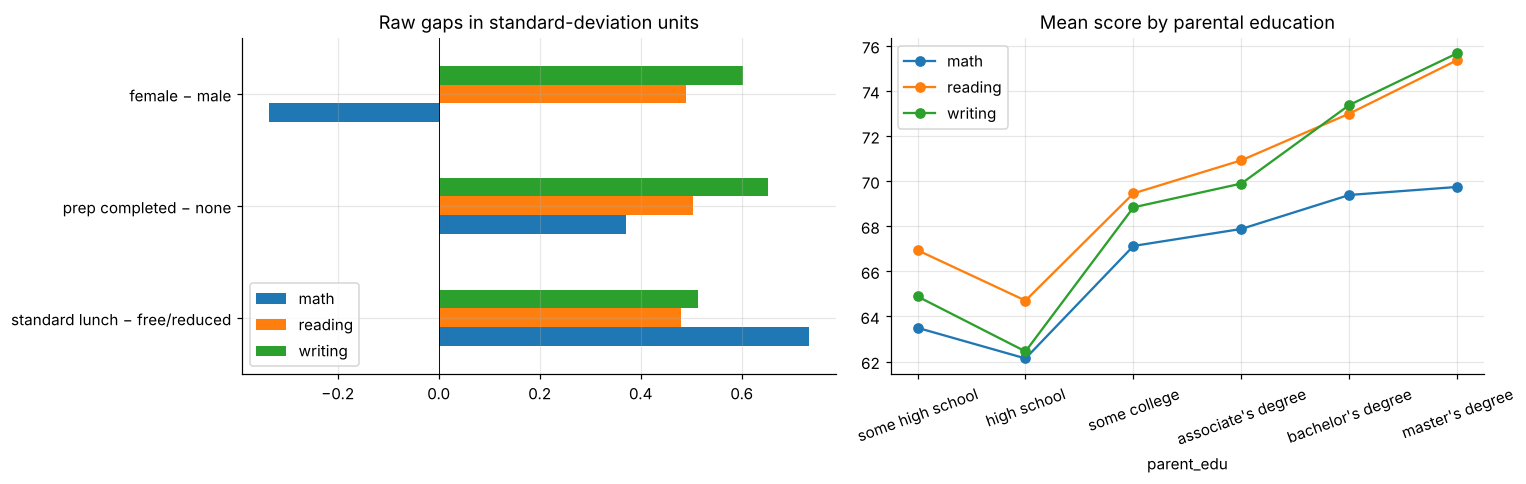

,math,reading,writing
standard lunch − free/reduced,0.73,0.48,0.51
prep completed − none,0.37,0.50,0.65
female − male,-0.34,0.49,0.60


In [2]:
def gap(col, a, b):
    return {subj: (s.loc[s[col] == a, subj + "_z"].mean() - s.loc[s[col] == b, subj + "_z"].mean()) for subj in ["math", "reading", "writing"]}
gaps = pd.DataFrame({"standard lunch − free/reduced": gap("lunch", "standard", "free/reduced"),
                     "prep completed − none": gap("prep", "completed", "none"),
                     "female − male": gap("gender", "female", "male")}).T
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
gaps.plot.barh(ax=axes[0], title="Raw gaps in standard-deviation units"); axes[0].axvline(0, c="k", lw=.6)
s.groupby("parent_edu", observed=True)[["math", "reading", "writing"]].mean().plot(ax=axes[1], marker="o", rot=20, title="Mean score by parental education")
plt.tight_layout(); plt.savefig(IMG / "gaps.png", bbox_inches="tight"); plt.show()
gaps.round(2)

## Is test prep associated with higher scores once background is held fixed?
Three estimates of the same quantity: raw difference, regression adjustment, and inverse-probability weighting (IPW) on a propensity score.

In [3]:
out = {}
for subj in ["math", "reading", "writing"]:
    raw = s.loc[s.prep_done == 1, subj].mean() - s.loc[s.prep_done == 0, subj].mean()
    reg = smf.ols(f"{subj} ~ prep_done + free_lunch + C(gender) + C(group) + C(parent_edu_s)", data=s).fit(cov_type="HC1")
    X = pd.get_dummies(s[["free_lunch", "gender", "group", "parent_edu"]].astype(str), drop_first=True).astype(float)
    ps = LogisticRegression(max_iter=1000).fit(X, s.prep_done).predict_proba(X)[:, 1]
    w = np.where(s.prep_done == 1, 1 / ps, 1 / (1 - ps))
    ipw = np.average(s[subj][s.prep_done == 1], weights=w[s.prep_done == 1]) - np.average(s[subj][s.prep_done == 0], weights=w[s.prep_done == 0])
    out[subj] = {"raw difference": raw, "regression-adjusted": reg.params["prep_done"], "95% CI": f"[{reg.conf_int().loc['prep_done', 0]:.1f}, {reg.conf_int().loc['prep_done', 1]:.1f}]", "IPW": ipw}
print(f"propensity scores range {ps.min():.2f}-{ps.max():.2f} (good overlap)")
pd.DataFrame(out).T

propensity scores range 0.24-0.53 (good overlap)


,raw difference,regression-adjusted,95% CI,IPW
math,5.618,5.495,"[3.8, 7.2]",5.446
reading,7.36,7.362,"[5.7, 9.0]",7.297
writing,9.914,10.059,"[8.5, 11.6]",10.025


In [4]:
m = smf.ols("math ~ free_lunch * prep_done + C(gender) + C(parent_edu_s)", data=s).fit(cov_type="HC1")
print(pd.DataFrame({"coef": m.params, "p": m.pvalues}).loc[["free_lunch", "prep_done", "free_lunch:prep_done"]].round(3))
share = s.groupby("free_lunch")["prep_done"].mean()
print(f"\nprep completion: standard lunch {share[0]:.1%} vs free/reduced {share[1]:.1%}")

                        coef      p
free_lunch           -11.548  0.000
prep_done              5.349  0.000
free_lunch:prep_done   0.958  0.609

prep completion: standard lunch 35.2% vs free/reduced 36.9%


## Findings
* **Income-proxy gap is the largest:** students on standard lunch score 0.73 SD higher in maths and about 0.5 SD higher in reading and writing than those on free/reduced lunch. Scores rise steadily with parental education.
* **Gender gaps point in opposite directions:** females trail by 0.34 SD in maths but lead by about 0.5-0.6 SD in reading and writing.
* **Test prep is associated with higher scores:** +5.5 points in maths, +7.4 in reading and +10.1 in writing. The raw, regression-adjusted and IPW estimates are almost identical, and the effect is no larger or smaller for free-lunch students (interaction p = 0.61).
* **Read that agreement with care.** The estimates agree because, in this fictional dataset, background barely predicts who takes the course (propensity scores only range from 0.24 to 0.53; completion is 35% vs 37% across lunch groups). In real schools, motivated or better-resourced students opt in. These would then be upper bounds, and a credible effect would need a randomised offer or a strong natural experiment.